# Matplotlib — Catch-Up Notebook (Class 17/9/2026)

This covers the full class in order:

1. `matplotlib.pyplot` basics and the figure/axes model
2. Line graphs
3. Bar charts
4. Scatter plots
5. Histograms
6. Customization: titles, axis labels, legends, gridlines, colors
7. Figure sizing
8. Multiple subplots with `plt.subplots()`

**Run every cell in order.** Exercises are at the bottom.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

print("Ready.")

Ready.


---
## 1. The figure/axes model

Almost everything in modern Matplotlib starts with one line:

```python
fig, ax = plt.subplots()
```

- **`fig`** — the whole canvas/window. You use it for things that affect the entire image:
  size (`fig.set_size_inches`), saving (`fig.savefig`), spacing between subplots.
- **`ax`** — one set of axes (one actual chart) that lives on the figure. You use it to draw
  data and customize that specific chart: `ax.plot()`, `ax.set_title()`, `ax.legend()`.

This is called the **object-oriented interface**, and it's the one to default to — it stays
predictable once you move from one chart to a grid of several (Section 8). You'll also see a
shortcut interface (`plt.plot(...)` directly, no `fig`/`ax`) in tutorials; it works for one
quick chart but gets confusing with subplots, so this notebook uses `ax.` consistently.

---
## 2. Line graphs — `ax.plot()`

Line charts are for showing how something changes over a continuous or ordered sequence
(time is the classic case).

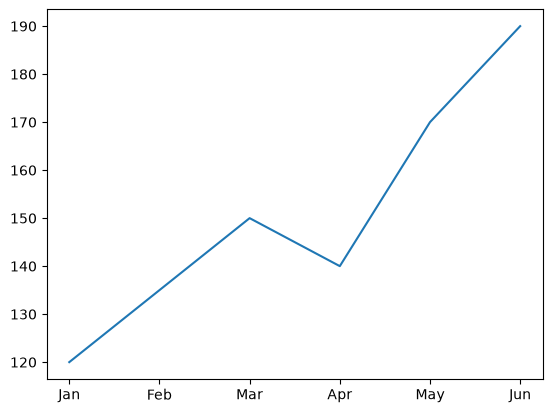

In [2]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales  = [120, 135, 150, 140, 170, 190]

fig, ax = plt.subplots()
ax.plot(months, sales)
plt.show()

That's the minimum. It's almost never enough on its own — a bare line with no labels tells
the reader nothing about what they're looking at. Section 6 fixes that. For now, two useful
`plot()` arguments to know:

- `marker="o"` — draws a dot at every data point (helps when you have few points)
- `linewidth=2` — thickness of the line

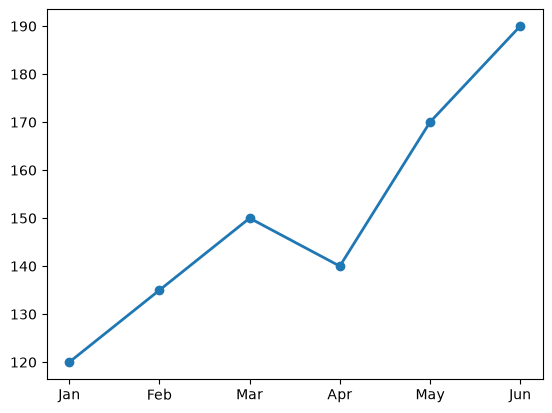

In [3]:
fig, ax = plt.subplots()
ax.plot(months, sales, marker="o", linewidth=2)
plt.show()

Multiple lines on one chart — just call `ax.plot()` again on the same `ax`:

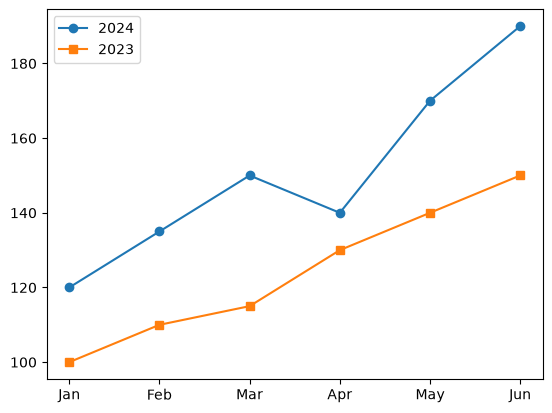

In [4]:
sales_2024 = [120, 135, 150, 140, 170, 190]
sales_2023 = [100, 110, 115, 130, 140, 150]

fig, ax = plt.subplots()
ax.plot(months, sales_2024, marker="o", label="2024")
ax.plot(months, sales_2023, marker="s", label="2023")
ax.legend()
plt.show()

---
## 3. Bar charts — `ax.bar()`

Bar charts are for comparing discrete categories against each other — not a trend over
continuous time, but distinct groups (cities, products, departments).

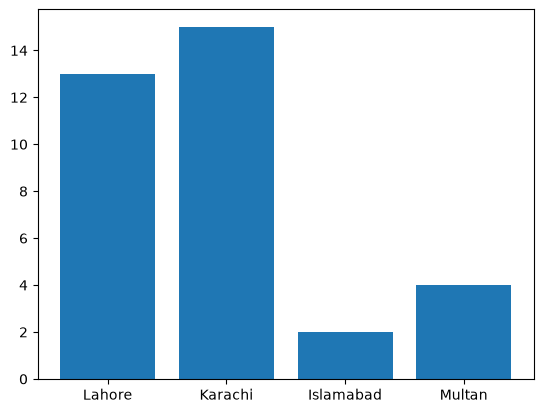

In [22]:
cities = ["Lahore", "Karachi", "Islamabad", "Multan"]
population_millions = [13, 15, 2, 4]

fig, ax = plt.subplots()
ax.bar(cities, population_millions)
plt.show()

`ax.barh()` gives horizontal bars instead — useful when category labels are long and would
overlap along the x-axis.

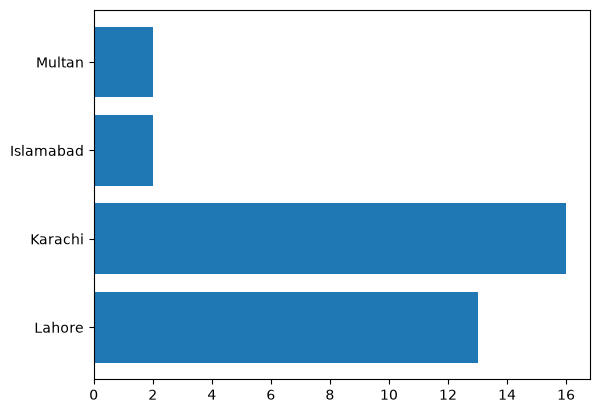

In [6]:
fig, ax = plt.subplots()
ax.barh(cities, population_millions)
plt.show()

---
## 4. Scatter plots — `ax.scatter()`

Scatter plots show the relationship between **two numeric variables** — each point is one
observation with an x and a y value. This is the go-to chart for spotting correlation.

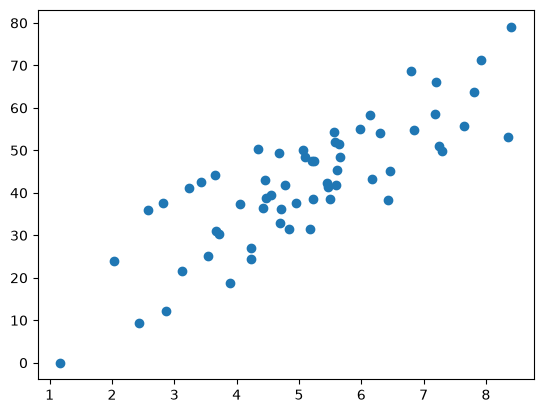

In [7]:
np.random.seed(0)
study_hours = np.random.normal(5, 1.5, 60)
exam_score  = study_hours * 8 + np.random.normal(0, 8, 60)

fig, ax = plt.subplots()
ax.scatter(study_hours, exam_score)
plt.show()

`alpha` (0 to 1) sets point transparency — essential once points start overlapping, since
darker patches then reveal where points are dense.

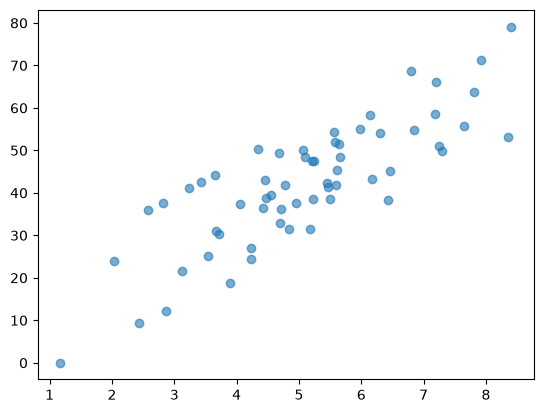

In [8]:
fig, ax = plt.subplots()
ax.scatter(study_hours, exam_score, alpha=0.6)
plt.show()

---
## 5. Histograms — `ax.hist()`

A histogram shows the **distribution** of a single numeric variable: it bins the values into
ranges and counts how many fall in each range. Don't confuse this with a bar chart — a bar
chart compares separate categories; a histogram shows the shape of one variable's spread.

`bins` controls how many buckets the range is split into. Too few bins hides structure; too
many makes it noisy.

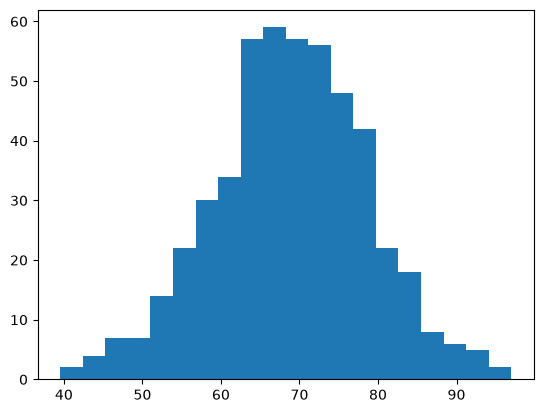

In [9]:
exam_scores = np.random.normal(70, 10, 500)

fig, ax = plt.subplots()
ax.hist(exam_scores, bins=20)
plt.show()

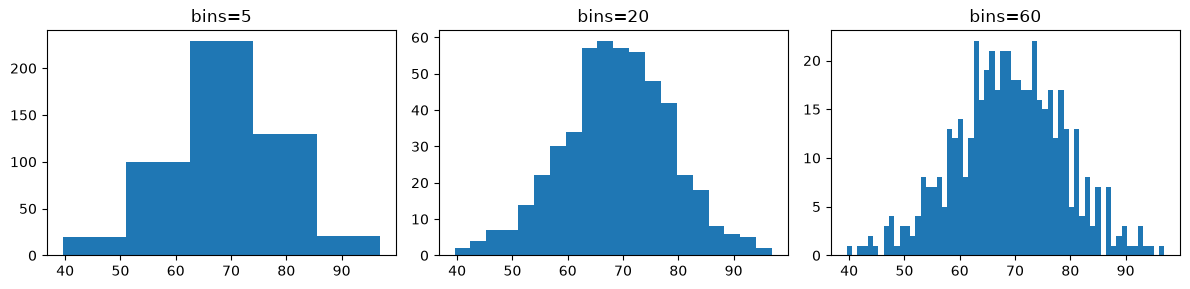

In [10]:
fig, axes_row = plt.subplots(1, 3, figsize=(12, 3))
for ax_i, b in zip(axes_row, [5, 20, 60]):
    ax_i.hist(exam_scores, bins=b)
    ax_i.set_title(f"bins={b}")
plt.tight_layout()
plt.show()

---
## 6. Customization: titles, labels, legends, grid, colors

A chart isn't presentation-ready until someone who's never seen your data can understand it
in five seconds. That means every chart needs, at minimum: a title, axis labels, and (if
there's more than one series) a legend.

Key `ax` methods:

| Method | Purpose |
|---|---|
| `ax.set_title("...")` | chart title |
| `ax.set_xlabel("...")`, `ax.set_ylabel("...")` | axis labels |
| `ax.legend()` | shows labels passed via `label=` in `plot`/`bar`/`scatter` |
| `ax.grid(True, alpha=0.3)` | gridlines (low alpha keeps them subtle, not distracting) |
| `color=` argument | line/bar/point color — accepts names (`"green"`), hex (`"#2563eb"`), or a list per bar |

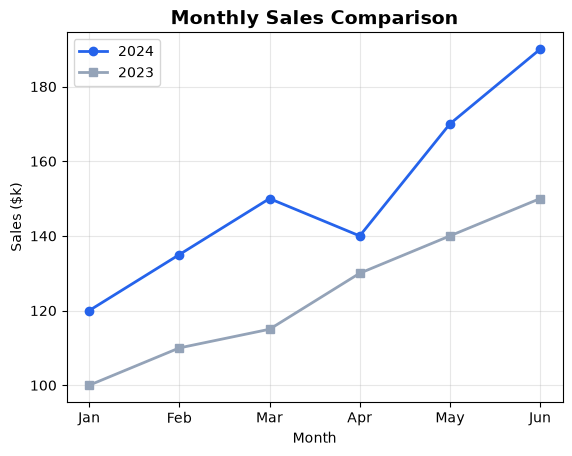

In [11]:
fig, ax = plt.subplots()

ax.plot(months, sales_2024, marker="o", color="#2563eb", linewidth=2, label="2024")
ax.plot(months, sales_2023, marker="s", color="#94a3b8", linewidth=2, label="2023")

ax.set_title("Monthly Sales Comparison", fontsize=14, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Sales ($k)")
ax.grid(True, alpha=0.3)
ax.legend()

plt.show()

A custom color palette applied per-bar — pass a **list** of colors the same length as the data:

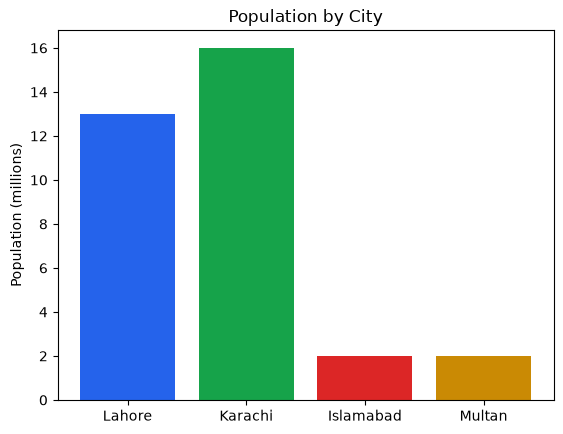

In [12]:
palette = ["#2563eb", "#16a34a", "#dc2626", "#ca8a04"]

fig, ax = plt.subplots()
ax.bar(cities, population_millions, color=palette)
ax.set_title("Population by City")
ax.set_ylabel("Population (millions)")
plt.show()

---
## 7. Figure sizing

`figsize=(width, height)` in inches, passed to `plt.subplots()`. A wide chart suits a long
time series; a near-square chart suits a scatter plot where you want x and y visually
comparable.

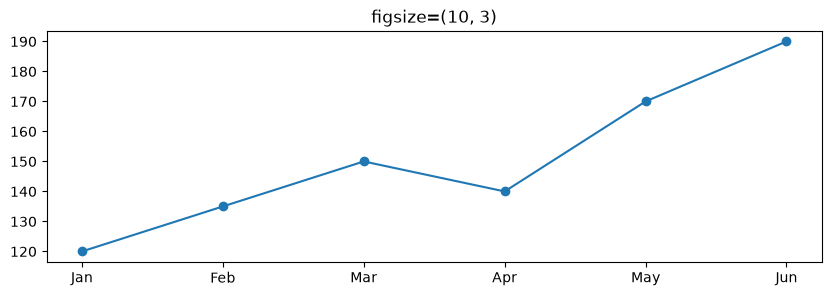

In [24]:
fig, ax = plt.subplots(figsize=(10, 3))   # wide and short
ax.plot(months, sales_2024, marker="o")
ax.set_title("figsize=(10, 3)")
plt.show()

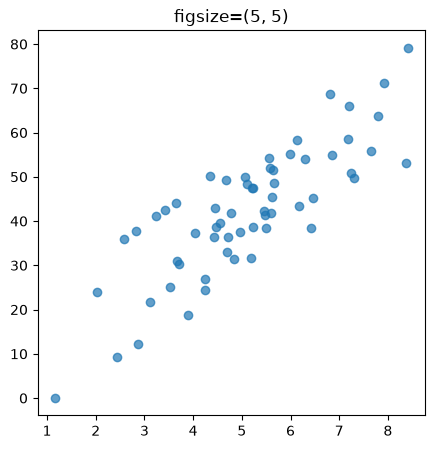

In [28]:
fig, ax = plt.subplots(figsize=(5, 5))    # square
ax.scatter(study_hours, exam_score, alpha=0.7)
ax.set_title("figsize=(5, 5)")
plt.show()

---
## 8. Multiple subplots with `plt.subplots()`

`plt.subplots(nrows, ncols)` builds a **grid** of axes in one call and returns them as a NumPy
array. This is how you put several related charts side by side for comparison.

- 1 row, several columns → `axes` is a 1D array, index with `axes[0]`, `axes[1]`, ...
- several rows and columns → `axes` is a 2D array, index with `axes[0, 0]`, `axes[0, 1]`, ...

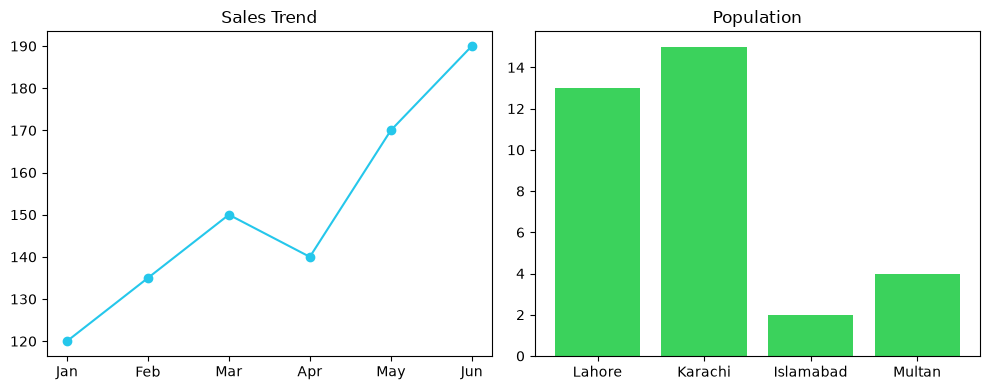

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(months, sales_2024, marker="o", color="#25c7eb")
axes[0].set_title("Sales Trend")

axes[1].bar(cities, population_millions, color="#3BD25CFF")
axes[1].set_title("Population")

plt.tight_layout()
plt.show()

A 2x2 grid — one of each chart type from this lesson, all in a single figure:

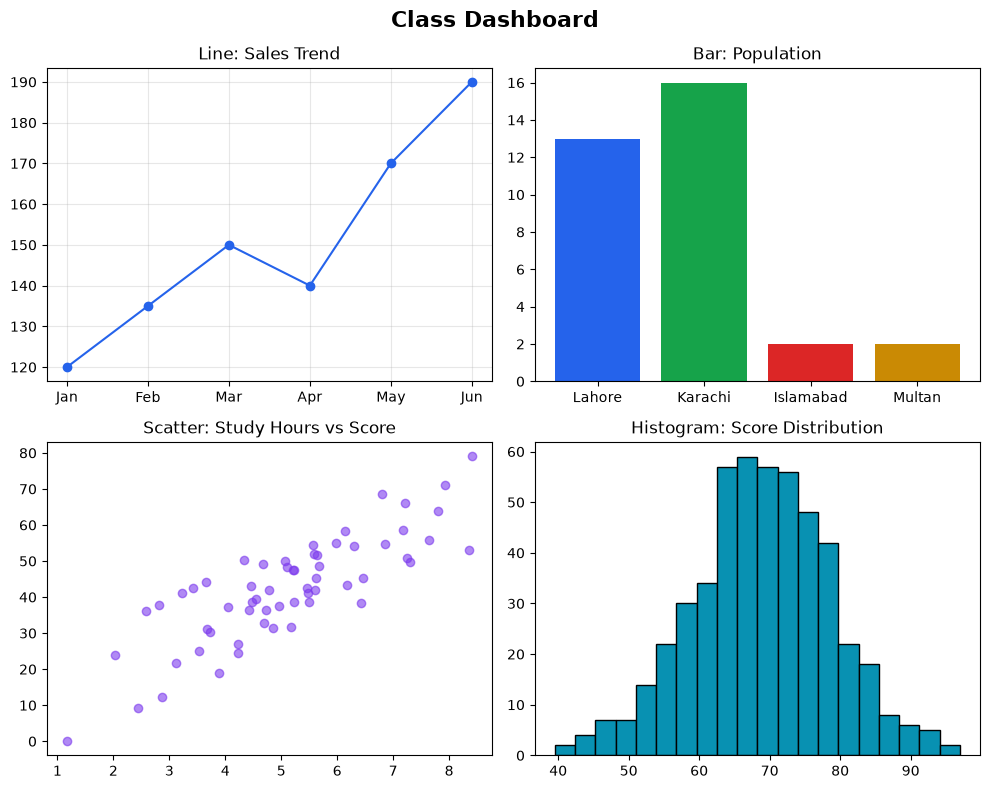

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes[0, 0].plot(months, sales_2024, marker="o", color="#2563eb")
axes[0, 0].set_title("Line: Sales Trend")
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].bar(cities, population_millions, color=palette)
axes[0, 1].set_title("Bar: Population")

axes[1, 0].scatter(study_hours, exam_score, alpha=0.6, color="#7c3aed")
axes[1, 0].set_title("Scatter: Study Hours vs Score")

axes[1, 1].hist(exam_scores, bins=20, color="#0891b2", edgecolor="black")
axes[1, 1].set_title("Histogram: Score Distribution")

fig.suptitle("Class Dashboard", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

`plt.tight_layout()` auto-adjusts spacing so titles/labels on one subplot don't overlap the
next one — call it right before `plt.show()`, after all subplots are drawn. `fig.suptitle()`
(note: on `fig`, not `ax`) adds one title over the whole grid.

**Saving a figure:** `fig.savefig("chart.png", dpi=150, bbox_inches="tight")` — `dpi` controls
resolution, `bbox_inches="tight"` trims excess whitespace around the figure.

---
## Quick reference

```python
fig, ax = plt.subplots(figsize=(w, h))       # one chart
fig, axes = plt.subplots(rows, cols, figsize=(w, h))  # grid of charts

ax.plot(x, y, marker="o", color="#2563eb", linewidth=2, label="Series")
ax.bar(categories, values, color=[...])
ax.barh(categories, values)
ax.scatter(x, y, alpha=0.6, color="...")
ax.hist(data, bins=20, color="...", edgecolor="black")

ax.set_title("..."); ax.set_xlabel("..."); ax.set_ylabel("...")
ax.legend(); ax.grid(True, alpha=0.3)

fig.suptitle("...")      # title over a whole grid
plt.tight_layout()
plt.show()
fig.savefig("out.png", dpi=150, bbox_inches="tight")
```

**Chart-type cheat sheet:**

| Question you're answering | Chart |
|---|---|
| How did this change over time/order? | Line |
| How do these categories compare? | Bar |
| Is there a relationship between two numeric variables? | Scatter |
| What's the shape/spread of one numeric variable? | Histogram |

**Three things likely to come up in a quiz:**

1. What's the difference between `fig` and `ax`? → `fig` is the whole canvas (size, saving); `ax` is one chart on it (data, title, labels).
2. Bar chart vs histogram — what's actually different? → Bar chart compares distinct categories; histogram bins one continuous variable into ranges and shows its distribution.
3. Why call `plt.tight_layout()`? → Prevents titles/labels on subplots from overlapping each other in a grid.

---
# Exercises

Try these yourself first. Solutions are in the last cell — don't peek.

In [17]:
np.random.seed(1)
weeks = ["W1","W2","W3","W4","W5","W6","W7","W8"]
temp_lahore = [22, 24, 27, 30, 34, 38, 36, 33]
temp_islamabad = [18, 20, 23, 26, 29, 31, 30, 27]

rainfall = {"Lahore": 45, "Karachi": 15, "Islamabad": 80, "Peshawar": 60}

heights = np.random.normal(165, 8, 200)   # cm

hours_worked = np.random.normal(6, 2, 80)
productivity = hours_worked * 10 + np.random.normal(0, 8, 80)

**Q1.** Plot `temp_lahore` and `temp_islamabad` against `weeks` as two lines on one chart, with
markers, a legend, title, and axis labels.

**Q2.** Make a bar chart of `rainfall` (dict of city → mm). Give each bar a different color from
a custom palette of your choice.

**Q3.** Make a histogram of `heights` with 25 bins, colored teal with black edges, and a title.

**Q4.** Make a scatter plot of `hours_worked` vs `productivity` with `alpha=0.5`, axis labels,
and a title.

**Q5.** Build a 2x2 `plt.subplots()` grid containing all four charts above (Q1–Q4), each with
its own title, and one overall `fig.suptitle()`. Use `figsize=(12, 9)` and `plt.tight_layout()`.

In [ ]:
# Your work here

---
### Solutions

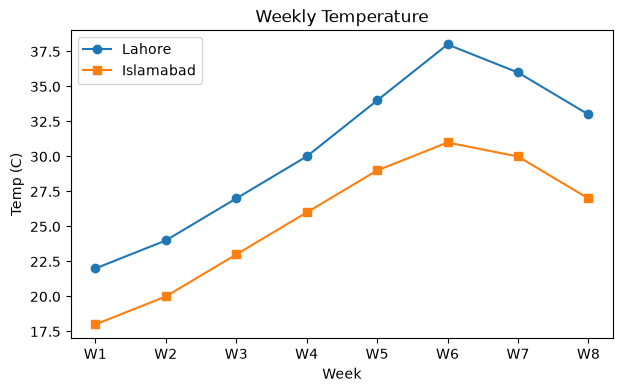

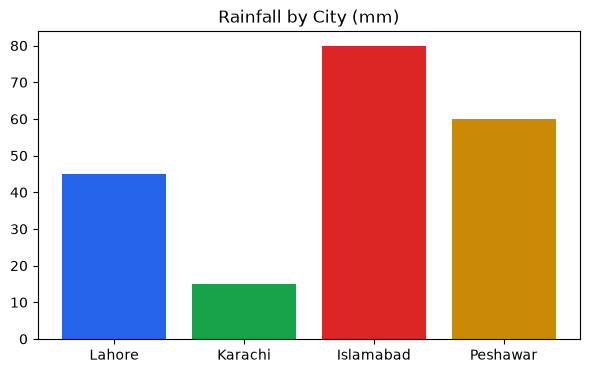

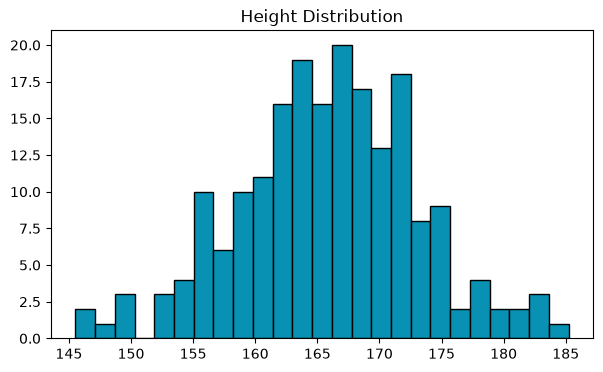

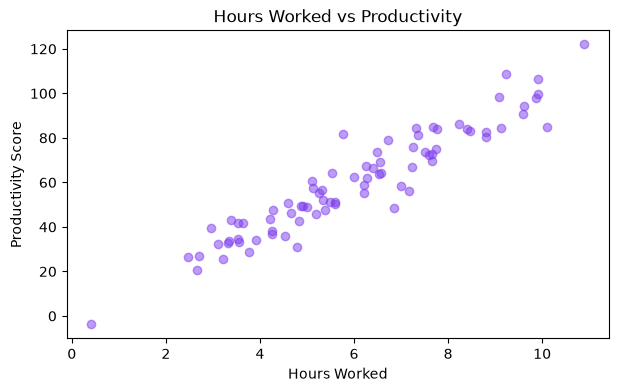

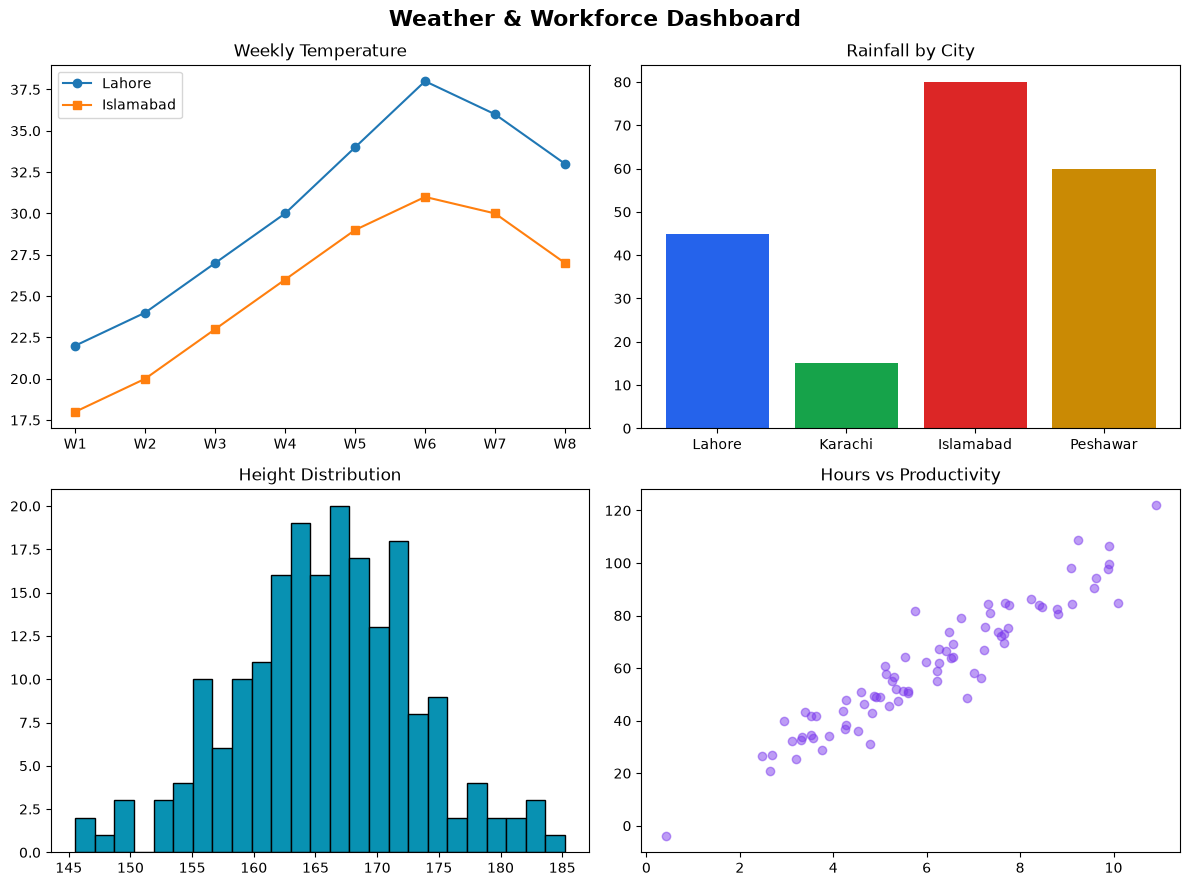

In [18]:
# Q1
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(weeks, temp_lahore, marker="o", label="Lahore")
ax.plot(weeks, temp_islamabad, marker="s", label="Islamabad")
ax.set_title("Weekly Temperature")
ax.set_xlabel("Week"); ax.set_ylabel("Temp (C)")
ax.legend()
plt.show()

# Q2
palette = ["#2563eb", "#16a34a", "#dc2626", "#ca8a04"]
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(list(rainfall.keys()), list(rainfall.values()), color=palette)
ax.set_title("Rainfall by City (mm)")
plt.show()

# Q3
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(heights, bins=25, color="#0891b2", edgecolor="black")
ax.set_title("Height Distribution")
plt.show()

# Q4
fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(hours_worked, productivity, alpha=0.5, color="#7c3aed")
ax.set_title("Hours Worked vs Productivity")
ax.set_xlabel("Hours Worked"); ax.set_ylabel("Productivity Score")
plt.show()

# Q5
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0,0].plot(weeks, temp_lahore, marker="o", label="Lahore")
axes[0,0].plot(weeks, temp_islamabad, marker="s", label="Islamabad")
axes[0,0].set_title("Weekly Temperature")
axes[0,0].legend()

axes[0,1].bar(list(rainfall.keys()), list(rainfall.values()), color=palette)
axes[0,1].set_title("Rainfall by City")

axes[1,0].hist(heights, bins=25, color="#0891b2", edgecolor="black")
axes[1,0].set_title("Height Distribution")

axes[1,1].scatter(hours_worked, productivity, alpha=0.5, color="#7c3aed")
axes[1,1].set_title("Hours vs Productivity")

fig.suptitle("Weather & Workforce Dashboard", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()